# How the shot analysis works

This notebook walks through `analyze_shot.py` step by step on one side-on video of a shot. Set the `SHOT_VIDEO` environment variable (or edit the path below) to use your own clip.

Everything drawn here is **skeleton-only**: the stick figure is rebuilt from joint positions on a plain background, so no pixels of the video (or the person) appear in the output.

```
video -> pose (MediaPipe) + ball (YOLO) per frame -> angles -> set point & release -> rule-based feedback
```

In [1]:
import os, sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
import cv2

from shotform.pose import PoseTracker
from shotform.ball import BallDetector
from shotform.analysis import track_video, find_key_frames, feedback, release_angles
from shotform.geometry import smooth
from shotform.render import draw_skeleton

VIDEO = os.environ.get("SHOT_VIDEO", "my_shot.mp4")
SIDE = "right"   # the shooting hand, as seen on camera

## 1. Track the body and the ball in every frame

In [2]:
tracker = PoseTracker(SIDE)
detector = BallDetector()          # fine-tuned weights if models/ball_yolov8n.pt exists, else generic YOLOv8
frames, info = track_video(VIDEO, tracker, detector)
tracker.close()
detected = sum(f.pose is not None for f in frames), sum(f.ball is not None for f in frames)
print(f"{len(frames)} frames at {info['fps']:.0f} fps; body found in {detected[0]}, ball found in {detected[1]}")

I0000 00:00:1792390039.105273 16329550 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M2
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


W0000 00:00:1792390039.186113 16329661 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792390039.203415 16329661 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


W0000 00:00:1792390041.440951 16329665 landmark_projection_calculator.cc:186] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


145 frames at 28 fps; body found in 145, ball found in 31


## 2. Measurements over time

Angles are computed from **pixel** coordinates. (Normalized 0-1 coordinates stretch angles on a tall phone video, which the first version of this project did not account for.)

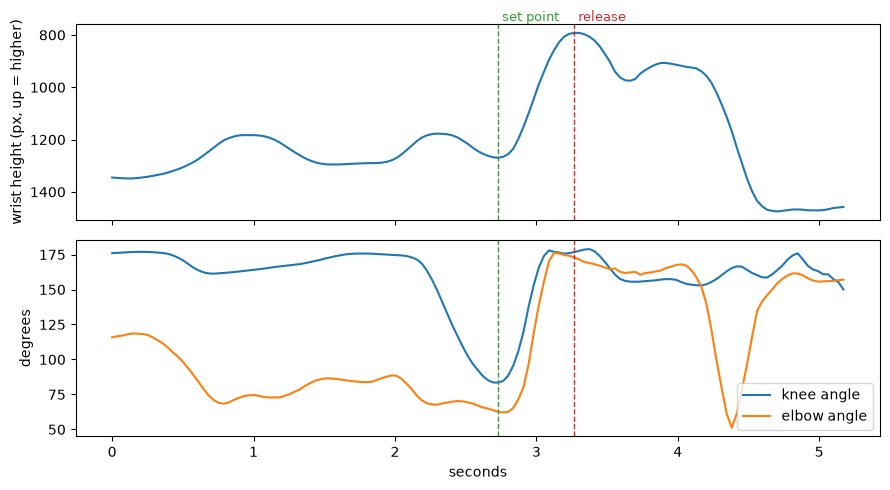

In [3]:
t = np.array([f.time for f in frames])
wrist_y = smooth([f.pose["wrist"][1] if f.pose else np.nan for f in frames])
knee = smooth([f.angles["knee"] for f in frames])
elbow = smooth([f.angles["elbow"] for f in frames])
set_i, release_i = find_key_frames(frames, info["fps"])

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(t, wrist_y); axes[0].invert_yaxis(); axes[0].set_ylabel("wrist height (px, up = higher)")
axes[1].plot(t, knee, label="knee angle"); axes[1].plot(t, elbow, label="elbow angle")
axes[1].set_ylabel("degrees"); axes[1].set_xlabel("seconds"); axes[1].legend()
for ax in axes:
    for i, name, color in [(set_i, "set point", "tab:green"), (release_i, "release", "tab:red")]:
        if i is not None:
            ax.axvline(t[i], color=color, ls="--", lw=1)
            if ax is axes[0]:
                ax.text(t[i], ax.get_ylim()[1], f" {name}", color=color, va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Find the two moments that matter

- **Release**: the last frame the ball is still in the shooting hand, just before the wrist reaches its highest point. (If the ball isn't detected, the wrist peak is used.)
- **Set point**: the deepest knee bend in the 3 seconds before the release, which is where the ball is loaded.

In [4]:
print(f"set point: frame {frames[set_i].index} ({t[set_i]:.2f}s)   release: frame {frames[release_i].index} ({t[release_i]:.2f}s)")

set point: frame 76 (2.73s)   release: frame 91 (3.27s)


## 4. Check the form against the rules

In [5]:
set_angles = frames[set_i].angles
rel = release_angles(frames[release_i].pose)
checks = feedback(set_angles, rel)
for c in checks:
    print(("PASS " if c["ok"] else "FAIL ") + f"{c['check']:<24} {c['value']:>6}°   {'' if c['ok'] else c['message']}")

FAIL set point: elbow           63.2°   Elbow should be close to a right angle (about 90 degrees) when you set the ball.
PASS set point: knee bend       81.2°   
PASS release: arm extension    171.3°   
PASS release: leg extension    176.0°   


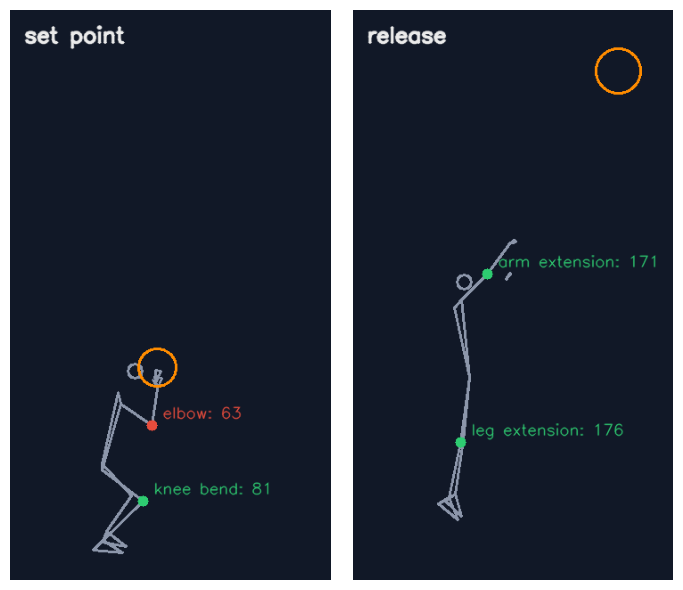

In [6]:
size = (info["width"], info["height"])
def marks(prefix):
    joint = {"elbow": "elbow", "knee bend": "knee", "arm extension": "elbow", "leg extension": "knee"}
    return [(joint[c["check"].split(": ")[1]], f"{c['check'].split(': ')[1]}: {c['value']:.0f}", c["ok"])
            for c in checks if c["check"].startswith(prefix) and c["value"] is not None]

imgs = [draw_skeleton(frames[set_i].pose, frames[set_i].ball, size, "set point", marks("set"), max_height=640),
        draw_skeleton(frames[release_i].pose, frames[release_i].ball, size, "release", marks("release"), max_height=640)]
fig, axes = plt.subplots(1, 2, figsize=(7, 6))
for ax, img in zip(axes, imgs):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off")
plt.tight_layout(); plt.show()

## What this can and can't do

- The thresholds in `shotform/analysis.py` are rules of thumb, loosely set from two professional reference clips. They are **not validated** against coach ratings or labelled shots, so treat the output as measurements with suggestions, not as a verdict.
- It assumes one shooter, a side-on camera and the whole body in frame.
- Pose estimation is noisy when the ball or arm hides a joint; `smooth()` handles short gaps, not long ones.
- A natural next step is to collect labelled good/bad shots and fit the thresholds (or a small classifier) on them.